In [1]:
import xarray as xr 
import numpy as np
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.pyplot as plt

from cmcrameri import cm as cmcra
import plotting_utils

In [2]:
# importing processed dataset
path_source = Path('../steady_out/') 
exp = 'NUH'
ds_NUH = xr.open_dataset(str(path_source / (exp + '.nc')))

exp = 'TEMP'
ds_TEMP = xr.open_dataset(str(path_source / (exp + '.nc')))

In [6]:
# define lists

NUH_list = [1.3, 6.4, 32] # e7 m^4/s

sfx_list = np.arange(0, 0.075+0.001, 0.005) # g/m^2/s

colors_plot =  np.flip(np.array(['#0072bd', '#d95319', '#77ac30']))

# Melt

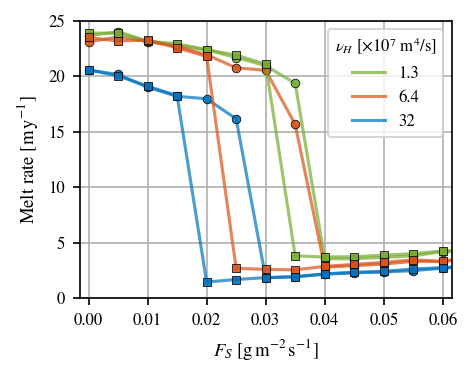

In [14]:
datasets = [
    (ds_NUH.melt_0D.sel(NUH=1.3), colors_plot[0], NUH_list[0]),
    (ds_TEMP.melt_0D.sel(T0=1), colors_plot[1], NUH_list[1]),
    (ds_NUH.melt_0D.sel(NUH=32), colors_plot[2], NUH_list[2]),
]

plt.figure(figsize=(3.2,2.4),dpi=150)


for i, marker in enumerate(['o', 's']):
    for data, color, label in datasets:

        y = data.isel(transition=i).values[:len(sfx_list)]

        plt.plot(
            sfx_list, y,
            color=color, alpha=0.7,
            label=label if i == 0 else None
        )

        plt.scatter(
            sfx_list, y,
            marker=marker,
            edgecolors='black',
            facecolors=color,
            lw=0.4, s=17,
            alpha=0.9, zorder=2,
        )



plt.xlabel(r'$F_S$ [$\mathrm{g\,m^{-2}\,s^{-1}}$]') 
plt.ylabel(r'Melt rate [$\mathrm{m\,y^{-1}}$]')


plt.xlim(0-0.0015,0.06+0.0015)
plt.ylim(0, 25)

plt.grid()

plt.legend(loc='upper right', title=r'$\nu_H$ [$\times 10^7$ $\mathrm{m^4/s}$]')

plt.savefig('./Figure11/NUH_melt.pdf', format='pdf', bbox_inches='tight')

plt.show()

# $\mathbf{u_\mathrm{tbl}}^2$

In [41]:
y_T = ds_NUH.y_T.values

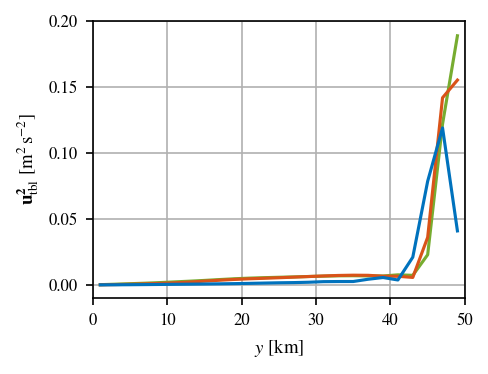

In [42]:
datasets = [
    (ds_NUH.utbl2_x50km.sel(NUH=1.3, Fs=0, transition="wtc"), colors_plot[0], NUH_list[0]),
    (ds_TEMP.utbl2_x50km.sel(T0=1, Fs=0, transition="wtc"), colors_plot[1], NUH_list[1]),
    (ds_NUH.utbl2_x50km.sel(NUH=32, Fs=0, transition="wtc"), colors_plot[2], NUH_list[2]),
]


plt.figure(figsize=(3.2,2.4),dpi=150)


for index in range(3):

    utbl2 = datasets[index][0].values
    color = datasets[index][1]
    label = datasets[index][2]

    plt.plot(y_T,utbl2, color=color, label=label)

plt.xlabel(r'$y$ [km]') 
plt.ylabel(r'$\mathbf{u^2_\mathrm{tbl}}$ [$\mathrm{m^2 \, s^{-2}}$]')


plt.xlim(0,50)
plt.ylim(-0.01, 0.2)

plt.grid()

#plt.legend(loc='upper left', title=r'$\nu_H$ [$\times 10^7$ $\mathrm{m^4/s}$]')

plt.savefig('./Figure11/NUH_utbl2.pdf', format='pdf', bbox_inches='tight')
plt.show()

# $T_\mathrm{bottom}$

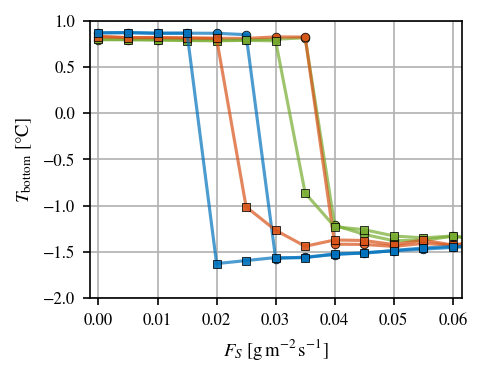

In [46]:
datasets = [
    (ds_NUH.T_bot.sel(NUH=1.3), colors_plot[0], NUH_list[0]),
    (ds_TEMP.T_bot.sel(T0=1), colors_plot[1], NUH_list[1]),
    (ds_NUH.T_bot.sel(NUH=32), colors_plot[2], NUH_list[2]),
]

plt.figure(figsize=(3.2,2.4),dpi=150)


for i, marker in enumerate(['o', 's']):
    for data, color, label in datasets:

        y = data.isel(transition=i).values[:len(sfx_list)]

        plt.plot(
            sfx_list, y,
            color=color, alpha=0.7,
            label=label if i == 0 else None
        )

        plt.scatter(
            sfx_list, y,
            marker=marker,
            edgecolors='black',
            facecolors=color,
            lw=0.4, s=17,
            alpha=0.9, zorder=2,
        )


plt.xlabel(r'$F_S$ [$\mathrm{g \, m^{-2} \, s^{-1}}$]') 
plt.ylabel(r'$T_\mathrm{bottom}$ [°C]')


plt.xlim(0-0.0015,0.06+0.0015)
plt.ylim(-2, 1)

plt.grid()

#plt.legend(loc='upper right', title=r'$\nu_H$ [$\times 10^7$ $\mathrm{m^4/s}$]')

plt.savefig('./Figure11/NUH_Tbottom.pdf', format='pdf', bbox_inches='tight')

plt.show()

# std w

In [52]:
depth_W = ds_NUH.depth_W

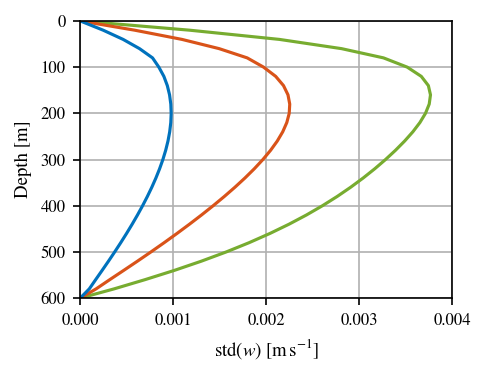

In [53]:
datasets = [
    (ds_NUH.w_std.sel(NUH=1.3, Fs=0.05, transition="ctw"), colors_plot[0], NUH_list[0]),
    (ds_TEMP.w_std.sel(T0=1, Fs=0.05, transition="ctw"), colors_plot[1], NUH_list[1]),
    (ds_NUH.w_std.sel(NUH=32, Fs=0.05, transition="ctw"), colors_plot[2], NUH_list[2]),
]

plt.figure(figsize=(3.2,2.4),dpi=150)


for index in range(3):

    std_w = datasets[index][0].values
    color = datasets[index][1]
    label = datasets[index][2]

    plt.plot(std_w, depth_W, color=color, label=label)

plt.ylabel(r'Depth [m]') 
plt.xlabel(r'$\mathrm{std}(w)$ [$\mathrm{m\,s^{-1}}$]')

ax = plt.gca()
ax.invert_yaxis()


plt.xlim(0,0.004)
plt.ylim(600, 0)

plt.grid()

#plt.legend(loc='upper left', title=r'$\nu_H$ [$\times 10^7$ $\mathrm{m^4/s}$]')

plt.savefig('./Figure11/NUH_std_w.pdf', format='pdf', bbox_inches='tight')

plt.show()